# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos Regresión para la Predicción de Precios de Casas**

**Integrantes del Equipo:**

* **Nombre y matrícula:** Edher Iván Díaz Salazar · A01840962
* **Nombre y matrícula:** Josué David del Valle Pimentel · A00833285
* **Nombre y matrícula:** Víctor Manuel Del Río González · A01840853
* **Nombre y matrícula:** Isaí Desales Santiago · A01840669

## 0. Preparación

Datos: `train.csv` del reto de Kaggle *House Prices – Advanced Regression Techniques* (1460 casas, 79 variables predictoras y `SalePrice`). Solo se usa `train.csv`, porque el `test.csv` de Kaggle no contiene `SalePrice`.

Si `train.csv` no está disponible en la sesión de Google Colab, la celda siguiente solicita subirlo manualmente. No se necesitan credenciales de Kaggle. Se requiere scikit-learn 1.4 o posterior.

In [ ]:
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV, learning_curve, cross_val_predict
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, PowerTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.inspection import permutation_importance
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from sklearn.base import clone
from xgboost import XGBRegressor

SEMILLA = 42
ANIO_ACTUAL = 2026

# Con drop="first", una categoría rara puede no aparecer en un fold.
# handle_unknown="ignore" la codifica de forma segura; se oculta solo ese aviso conocido.
warnings.filterwarnings(
    "ignore",
    message="Found unknown categories in columns.*",
    category=UserWarning,
    module="sklearn.preprocessing._encoders",
)

# Misma carga manual utilizada originalmente.
RUTA_DATOS = "train.csv"

if not os.path.exists(RUTA_DATOS):
    from google.colab import files

    print("Selecciona el archivo train.csv")
    files.upload()

print(
    f"Python {sys.version.split()[0]} | pandas {pd.__version__} | "
    f"scikit-learn {sklearn.__version__} | XGBoost {xgboost.__version__}"
)
print(f"Datos de entrenamiento: {os.path.abspath(RUTA_DATOS)}")

Python 3.13.18 | pandas 2.2.3 | scikit-learn 1.6.1 | XGBoost 3.4.1
Datos de entrenamiento: /content/train.csv


In [ ]:
df = pd.read_csv(RUTA_DATOS)
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1–3. Variables temporales

**1. `YrSold`.** Se elimina. La actividad simula una valuación en un momento fijo, y el año de venta solo describe cuándo ocurrió la transacción (2006–2010 en estos datos), no una característica de la casa. Si se dejara, el modelo aprendería efectos de mercado de esos años que no aplican a una valuación en 2026.

**2. `YearBuilt` y `YearRemodAdd`.** Se convierten en `AgeHouse = 2026 − YearBuilt` y `AgeRemod = 2026 − YearRemodAdd`, que expresan lo que importa al valuar (qué tan nueva es la casa o su remodelación) sin depender del calendario. Después **se eliminan las originales**: cada edad es una transformación lineal exacta de su año, así que conservar ambas duplica información y genera colinealidad perfecta en la regresión lineal sin aportar nada a los demás modelos.

Por la misma razón, `GarageYrBlt` (año calendario del garaje, con faltantes cuando no hay garaje y muy parecido a `YearBuilt`) también se elimina.

**3. `MoSold`.** Se comparan con validación cruzada las cuatro opciones que pide la actividad (numérica, eliminar, categórica, cíclica seno/coseno) en la celda siguiente. El mes es cíclico (diciembre está junto a enero), así que si se conserva conviene la codificación seno/coseno y **eliminar la original**, porque ya está contenida en las dos nuevas y como número sugiere un orden falso (12 > 1).

**Decisión:** con la partición estratificada, la tabla de la celda siguiente da el menor RMSE de validación a la codificación **cíclica** (33,844 USD), seguida de categórica (34,037), numérica (34,160) y eliminar (34,167). Se usa la cíclica, aunque la diferencia entre la mejor y la peor es menor a 1 %: el mes de venta aporta poca señal frente a las características físicas de la vivienda.

In [ ]:
NINGUNO = {  # en data_description.txt de Kaggle, NA significa ausencia, no dato perdido
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond", "PoolQC", "Fence", "MiscFeature", "MasVnrType",
}
CALIDAD = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "None": 0}
ORDINALES = {
    **{c: CALIDAD for c in ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual",
                            "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]},
    "BsmtExposure": {"Gd": 4, "Av": 3, "Mn": 2, "No": 1, "None": 0},
    "BsmtFinType1": {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1, "None": 0},
    "BsmtFinType2": {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1, "None": 0},
    "GarageFinish": {"Fin": 3, "RFn": 2, "Unf": 1, "None": 0},
}

def preparar(datos, opcion_mes="ciclica"):
    """Transformaciones deterministas (sin estadísticos aprendidos), por eso no filtran información."""
    d = datos.drop(columns=["Id", "SalePrice", "YrSold", "GarageYrBlt"], errors="ignore").copy()  # SalePrice es el objetivo: nunca entra como variable
    d["AgeHouse"] = ANIO_ACTUAL - d.pop("YearBuilt")
    d["AgeRemod"] = ANIO_ACTUAL - d.pop("YearRemodAdd")
    mes = d.pop("MoSold")
    if opcion_mes == "numerica":
        d["MoSold"] = mes
    elif opcion_mes == "categorica":
        d["MoSold"] = mes.astype(str)
    elif opcion_mes == "ciclica":
        d["MoSold_sin"] = np.sin(2 * np.pi * mes / 12)
        d["MoSold_cos"] = np.cos(2 * np.pi * mes / 12)
    for c in NINGUNO & set(d.columns):
        d[c] = d[c].fillna("None")
    if {"MasVnrArea", "MasVnrType"} <= set(d.columns):  # sin recubrimiento -> área 0
        d.loc[d["MasVnrType"].eq("None") & d["MasVnrArea"].isna(), "MasVnrArea"] = 0
    for c, mapa in ORDINALES.items():
        if c in d:
            d[c] = d[c].map(mapa).astype(float)
    d["MSSubClass"] = d["MSSubClass"].astype(str)  # código de tipo de vivienda, no cantidad
    return d

y = df["SalePrice"]
# Estratos solo para repartir precios de forma semejante entre train y test.
# SalePrice no se incorpora como característica del modelo.
ESTRATO_PRECIO = pd.qcut(y, q=10, labels=False, duplicates="drop")

faltantes = df.isna().mean().sort_values(ascending=False)
faltantes[faltantes > 0].to_frame("proporción NA").round(3)

,proporción NA
PoolQC,0.995
MiscFeature,0.963
Alley,0.938
Fence,0.808
MasVnrType,0.597
FireplaceQu,0.473
LotFrontage,0.177
GarageQual,0.055
GarageFinish,0.055
GarageType,0.055


## 4–6. Limpieza, imputación y transformaciones

###Nota
Se conservaron todas las viviendas, incluidas aquellas con `GrLivArea > 4000`. Eliminarlas cambiaría el alcance del problema y dejaría al modelo sin ejemplos de propiedades grandes. Estas observaciones pueden aumentar el RMSE y la variabilidad entre folds, por lo que el desempeño por rango de precio y superficie debe revisarse antes de un uso productivo. No se reportan cifras de un experimento alternativo porque esa eliminación no forma parte del flujo final reproducible.

Aun así, se decidió conservarlas, sabiendo que esto afecta el desempeño de los modelos, sobre todo de los lineales, porque eliminarlas limitaría el alcance del sistema a casas de hasta 4,000 ft² y lo dejaría sin capacidad para valuar propiedades grandes. Por esta razón, los resultados muestran una mayor variabilidad entre folds, y los modelos basados en árboles, que son más robustos ante valores extremos, resultan favorecidos.

**4. Decisiones** (todas las que aprenden algo de los datos van dentro del `Pipeline`, así que se ajustan solo con el pliegue de entrenamiento):

- **Faltantes por ausencia** (sótano, garaje, alberca, chimenea, cerca, etc.): se reemplazan por la categoría `"None"` y en las ordinales por 0, porque según la descripción de Kaggle NA significa «no tiene». Imputar la moda inventaría un garaje o una alberca que no existen.
- **`MasVnrArea`**: 0 cuando tampoco hay tipo de recubrimiento (no tiene).
- **Faltantes reales numéricos** (como `LotFrontage`): **mediana**, porque las áreas tienen colas largas y la media se ve jalada por casas muy grandes.
- **Faltantes reales categóricos** (`Electrical`, un registro): **moda**.
- **Ordinales** (calidad, exposición, acabados): mapeo numérico que respeta el orden (Po < Fa < TA < Gd < Ex).
- **Nominales**: One-Hot-Encoding con `handle_unknown="ignore"`.
- **Numéricas**: para lineales, MLP y SVR se usa `PowerTransformer(method="yeo-johnson", standardize=True)`. El mismo transformador reduce asimetría y estandariza; no se aplica un `StandardScaler` adicional. Los árboles no necesitan escalamiento.
- **Objetivo**: los modelos se entrenan con `log(1 + SalePrice)` (precio muy asimétrico) mediante `TransformedTargetRegressor`; **todas las métricas se reportan en dólares**.

**5. `PoolQC` y `GarageType`.** `PoolQC` tiene más del 99 % de NA porque casi ninguna casa tiene alberca: NA = «sin alberca», así que se codifica como 0 en la escala ordinal y no se imputa con moda ni se elimina la fila. `GarageType` tiene NA en las casas sin garaje (las mismas filas con NA en el resto de variables de garaje): se asigna la categoría `"None"`, que conserva la información de que no hay garaje.

**6. `drop` en One-Hot-Encoding.** En la regresión lineal sin regularización se usa `drop="first"`: con todas las columnas dummy, su suma es igual al intercepto (trampa de variables ficticias) y los coeficientes no son identificables. Con regularización (Ridge/Lasso), redes y SVM la colinealidad no impide el ajuste, y en **árboles conviene `drop=None`**: quitar una categoría obliga al árbol a reconocerla solo como «todas las demás son 0», lo que vuelve las particiones más difíciles e interpretables a medias.

In [ ]:
def preprocesador(escalar, drop=None):
    num = Pipeline([("imp", SimpleImputer(strategy="median"))]
                   + ([("pt", PowerTransformer(method="yeo-johnson"))] if escalar else []))
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("ohe", OneHotEncoder(handle_unknown="ignore", drop=drop, sparse_output=False))])
    return ColumnTransformer([("num", num, make_column_selector(dtype_include=np.number)),
                              ("cat", cat, make_column_selector(dtype_exclude=np.number))])

def modelo(regresor, escalar, drop=None):
    pipe = Pipeline([("prep", preprocesador(escalar, drop)), ("reg", regresor)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

# Comparación de opciones para MoSold con un modelo lineal regularizado.
# Se utiliza exactamente el mismo 80 % estratificado que formará X_train.
X_tmp, _, y_tmp, _ = train_test_split(
    df, y, test_size=0.2, random_state=SEMILLA, stratify=ESTRATO_PRECIO
)
cv = KFold(5, shuffle=True, random_state=SEMILLA)
filas = []
for opcion in ["numerica", "eliminar", "categorica", "ciclica"]:
    Xo = preparar(X_tmp, opcion)
    gs = GridSearchCV(modelo(Ridge(), True), {"regressor__reg__alpha": [1, 10, 30]}, cv=cv,
                      scoring="neg_root_mean_squared_error").fit(Xo, y_tmp)
    filas.append({"MoSold": opcion, "RMSE_CV": -gs.best_score_})
comparacion_mes = pd.DataFrame(filas).sort_values("RMSE_CV")
OPCION_MES = comparacion_mes.iloc[0]["MoSold"]  # la de menor RMSE en validación cruzada
X_completo = preparar(df, OPCION_MES)
print("Opción elegida para MoSold:", OPCION_MES)
comparacion_mes

Opción elegida para MoSold: ciclica


,MoSold,RMSE_CV
3,ciclica,33844.132904
2,categorica,34036.720722
0,numerica,34160.437067
1,eliminar,34167.319676


## 7. Partición

Se reserva 80 % para entrenamiento y 20 % para prueba. La separación se estratifica con diez cuantiles de `SalePrice` para repartir de manera semejante viviendas económicas, medias y costosas. El precio se utiliza solamente para construir los estratos; nunca entra como característica del modelo.

El ajuste de hiperparámetros usa **validación cruzada de cinco pliegues dentro del 80 %**, así que no hace falta un conjunto de validación aparte. El 20 % de prueba queda fuera de la selección de modelos, hiperparámetros e interpretación; se utiliza una sola vez para reportar las métricas finales.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_completo,
    y,
    test_size=0.2,
    random_state=SEMILLA,
    stratify=ESTRATO_PRECIO,
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Mediana SalePrice - train:", round(y_train.median()), "| test:", round(y_test.median()))

Train: (1168, 78) | Test: (292, 78)
Mediana SalePrice - train: 163000 | test: 163495


## 8. Modelo base (ingenuo)

Predice siempre la media del precio de entrenamiento; cualquier modelo útil debe tener un RMSE claramente menor.

In [ ]:
base = DummyRegressor(strategy="mean").fit(X_train, y_train)
rmse_base = root_mean_squared_error(y_test, base.predict(X_test))
print(f"RMSE modelo base (media): {rmse_base:,.0f} USD")

RMSE modelo base (media): 80,068 USD


## 9. Entrenamiento y ajuste de cada modelo

Para cada modelo se realiza búsqueda de hiperparámetros con RMSE, validación cruzada de cinco pliegues, curva de aprendizaje y evaluación final. Todo el preprocesamiento está dentro del pipeline para evitar fuga de información.

Se distinguen dos cálculos:

- `RMSE_CV_media_folds`: promedio de los cinco RMSE utilizado por `GridSearchCV` o `RandomizedSearchCV` para elegir hiperparámetros.
- `RMSE_OOF`: un único RMSE calculado al reunir todas las predicciones fuera de fold de `cross_val_predict`.

Ambos usan solamente train, pero pueden diferir porque “promediar cinco RMSE” no es exactamente igual que “calcular un RMSE global con todas las predicciones OOF”. La selección de modelos usa las métricas OOF; test se reporta aparte.

In [ ]:
resultados, mejores, busquedas = [], {}, {}

def curva_aprendizaje(nombre, estimador):
    tam, tr, va = learning_curve(estimador, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error",
                                 train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)
    plt.figure(figsize=(6, 4))
    plt.plot(tam, -tr.mean(axis=1), "o-", label="Entrenamiento")
    plt.plot(tam, -va.mean(axis=1), "o-", label="Validación")
    plt.title(f"Curva de aprendizaje · {nombre}"); plt.xlabel("Casas de entrenamiento"); plt.ylabel("RMSE (USD)")
    plt.legend(); plt.grid(alpha=.3); plt.show()

def entrenar(nombre, estimador, rejilla, aleatoria=False, n_iter=25):
    t0 = time.perf_counter()
    if aleatoria:
        bus = RandomizedSearchCV(estimador, rejilla, n_iter=n_iter, cv=cv, scoring="neg_root_mean_squared_error",
                                 random_state=SEMILLA, n_jobs=-1)
    else:
        bus = GridSearchCV(estimador, rejilla, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    bus.fit(X_train, y_train)
    t_busqueda = time.perf_counter() - t0
    mejor = bus.best_estimator_
    t0 = time.perf_counter(); clone(mejor).fit(X_train, y_train); t_fit = time.perf_counter() - t0
    # Predicciones fuera de fold con el mejor conjunto de hiperparámetros.
    # Se reportan aparte del promedio de RMSE usado por la búsqueda.
    oof = cross_val_predict(mejor, X_train, y_train, cv=cv, n_jobs=-1)
    pred = mejor.predict(X_test)
    resultados.append({
        "modelo": nombre,
        "RMSE_CV_media_folds": -bus.best_score_,
        "RMSE_OOF": root_mean_squared_error(y_train, oof),
        "MAE_OOF": mean_absolute_error(y_train, oof),
        "RMSE": root_mean_squared_error(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred),
        "MAPE": mean_absolute_percentage_error(y_test, pred),
        "t_entrenamiento_s": t_fit,
        "t_busqueda_s": t_busqueda,
    })
    mejores[nombre], busquedas[nombre] = mejor, bus
    tabla = pd.DataFrame(bus.cv_results_)
    cols = [c for c in tabla if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
    top = tabla.sort_values("rank_test_score")[cols].head(5).copy()
    top["mean_test_score"] = -top["mean_test_score"]
    display(top.rename(columns={
        "mean_test_score": "RMSE_CV_media_folds",
        "std_test_score": "desv_RMSE_folds",
    }))
    print("Mejores hiperparámetros:", bus.best_params_)
    curva_aprendizaje(nombre, mejor)
    display(pd.DataFrame([resultados[-1]]).round(3))

### 9a. Regresión lineal múltiple con estabilización numérica

La regresión ordinaria resultó inestable en algunos entornos de Colab: las numerosas columnas One-Hot producen una matriz casi singular y, al invertir `log1p` con `expm1`, algunas predicciones extremas se convierten en infinito. Se utiliza `Ridge(alpha=1e-6)`, una penalización prácticamente nula que conserva el comportamiento lineal y evita el fallo numérico. No debe confundirse con el modelo Ridge ajustado posteriormente, cuyo `alpha` se selecciona mediante validación cruzada.

,RMSE_CV_media_folds,desv_RMSE_folds
0,36827.054402,17154.162458


Mejores hiperparámetros: {}


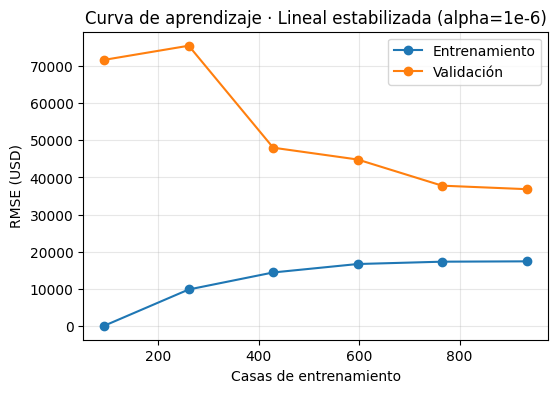

,modelo,RMSE_CV_media_folds,RMSE_OOF,MAE_OOF,RMSE,MAE,R2,MAPE,t_entrenamiento_s,t_busqueda_s
0,Lineal estabilizada (alpha=1e-6),36827.054,40645.731,16812.392,25430.936,16107.878,0.899,0.089,0.26,1.281


In [ ]:
entrenar(
    "Lineal estabilizada (alpha=1e-6)",
    modelo(Ridge(alpha=1e-6), True, drop="first"),
    {},
)

,param_regressor__reg__alpha,RMSE_CV_media_folds,desv_RMSE_folds
2,10,33844.132904,11091.928676
1,3,33970.546044,11790.494111
3,30,34246.628619,11066.213294
0,1,34339.336094,13537.283300
4,100,35128.818371,10738.550123


Mejores hiperparámetros: {'regressor__reg__alpha': 10}


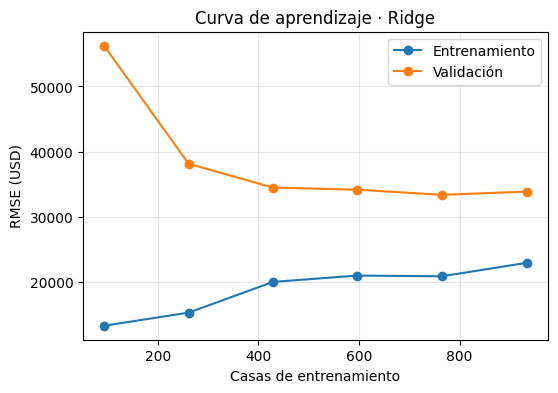

,modelo,RMSE_CV_media_folds,RMSE_OOF,MAE_OOF,RMSE,MAE,R2,MAPE,t_entrenamiento_s,t_busqueda_s
0,Ridge,33844.133,35623.904,15942.745,24643.029,15161.25,0.905,0.082,0.333,8.227


In [ ]:
entrenar("Ridge", modelo(Ridge(), True), {"regressor__reg__alpha": [1, 3, 10, 30, 100]})

,param_regressor__reg__alpha,RMSE_CV_media_folds,desv_RMSE_folds
2,0.0010,32577.399230,9576.018537
1,0.0003,33308.924457,14081.322363
0,0.0001,34191.229079,16448.126658
3,0.0030,34229.075377,9165.211782


Mejores hiperparámetros: {'regressor__reg__alpha': 0.001}


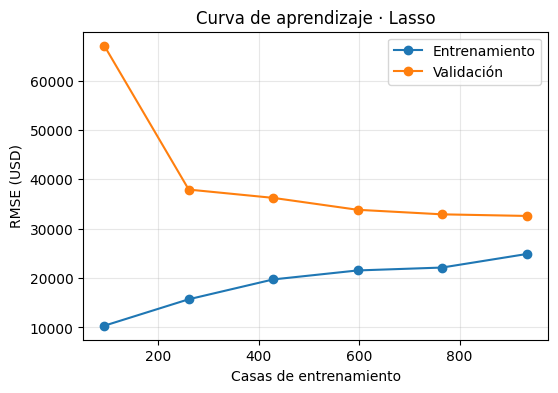

,modelo,RMSE_CV_media_folds,RMSE_OOF,MAE_OOF,RMSE,MAE,R2,MAPE,t_entrenamiento_s,t_busqueda_s
0,Lasso,32577.399,33961.998,15927.614,25482.662,15306.704,0.899,0.083,0.212,6.089


In [ ]:
entrenar("Lasso", modelo(Lasso(max_iter=20000), True), {"regressor__reg__alpha": [1e-4, 3e-4, 1e-3, 3e-3]})

### 9b. Árbol de decisión

,param_regressor__reg__max_depth,param_regressor__reg__min_samples_leaf,RMSE_CV_media_folds,desv_RMSE_folds
8,8,1,38592.784767,2356.469700
15,12,20,39546.209556,3623.282048
19,None,20,39546.209556,3623.282048
11,8,20,39573.483399,3639.731783
18,None,10,39795.397971,4514.197625


Mejores hiperparámetros: {'regressor__reg__max_depth': 8, 'regressor__reg__min_samples_leaf': 1}


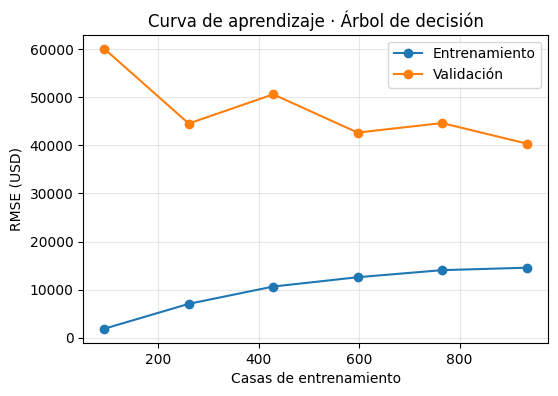

,modelo,RMSE_CV_media_folds,RMSE_OOF,MAE_OOF,RMSE,MAE,R2,MAPE,t_entrenamiento_s,t_busqueda_s
0,Árbol de decisión,38592.785,38663.337,26662.071,32802.526,22773.305,0.832,0.133,0.073,9.582


In [ ]:
entrenar("Árbol de decisión", modelo(DecisionTreeRegressor(random_state=SEMILLA), False), {"regressor__reg__max_depth": [4, 6, 8, 12, None], "regressor__reg__min_samples_leaf": [1, 5, 10, 20]})

### 9c. Bosque aleatorio

,param_regressor__reg__max_features,param_regressor__reg__min_samples_leaf,RMSE_CV_media_folds,desv_RMSE_folds
3,0.5,1,30892.646299,3497.306314
0,0.3,1,31348.964138,3675.937652
4,0.5,2,31550.214861,3489.312331
1,0.3,2,31727.631602,3536.190242
5,0.5,4,32349.050857,3529.832367


Mejores hiperparámetros: {'regressor__reg__max_features': 0.5, 'regressor__reg__min_samples_leaf': 1}


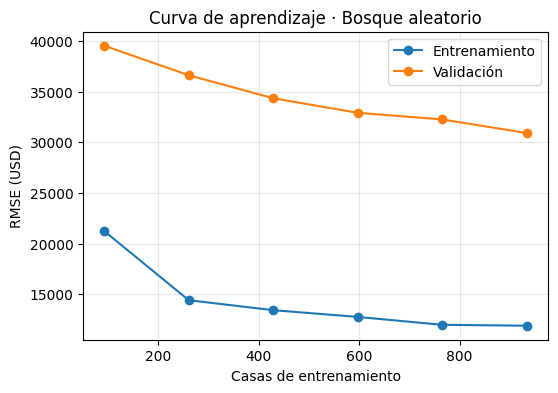

,modelo,RMSE_CV_media_folds,RMSE_OOF,MAE_OOF,RMSE,MAE,R2,MAPE,t_entrenamiento_s,t_busqueda_s
0,Bosque aleatorio,30892.646,31085.183,17446.111,24818.104,15148.606,0.904,0.087,5.382,110.867


In [ ]:
entrenar("Bosque aleatorio", modelo(RandomForestRegressor(n_estimators=300, random_state=SEMILLA, n_jobs=-1), False), {"regressor__reg__max_features": [0.3, 0.5, "sqrt"], "regressor__reg__min_samples_leaf": [1, 2, 4]})

### 9d. XGBoost

,param_regressor__reg__subsample,param_regressor__reg__reg_lambda,param_regressor__reg__n_estimators,param_regressor__reg__max_depth,param_regressor__reg__learning_rate,param_regressor__reg__colsample_bytree,RMSE_CV_media_folds,desv_RMSE_folds
16,0.85,5.0,1000,4,0.10,0.3,27134.508984,3729.270314
14,1.00,5.0,1000,3,0.10,0.3,27278.589844,3835.867783
19,0.85,1.0,1500,3,0.05,0.8,27332.437500,3570.787077
3,0.85,1.0,1000,3,0.05,0.8,27421.428906,3574.290916
5,0.85,1.0,1500,3,0.05,0.5,27558.574219,3805.774635


Mejores hiperparámetros: {'regressor__reg__subsample': 0.85, 'regressor__reg__reg_lambda': 5, 'regressor__reg__n_estimators': 1000, 'regressor__reg__max_depth': 4, 'regressor__reg__learning_rate': 0.1, 'regressor__reg__colsample_bytree': 0.3}


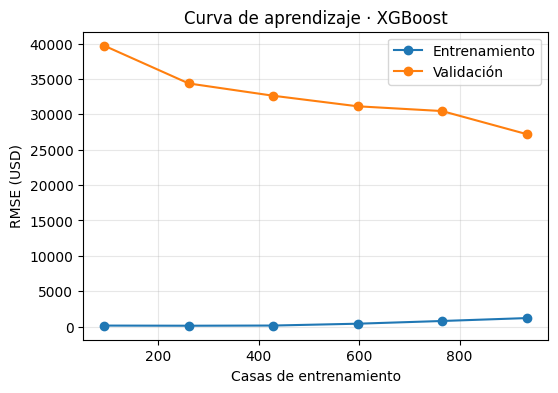

,modelo,RMSE_CV_media_folds,RMSE_OOF,MAE_OOF,RMSE,MAE,R2,MAPE,t_entrenamiento_s,t_busqueda_s
0,XGBoost,27134.509,27384.484,15779.572,24916.023,14456.164,0.903,0.081,1.459,97.271


In [ ]:
entrenar("XGBoost", modelo(XGBRegressor(random_state=SEMILLA, n_jobs=-1, tree_method="hist"), False), {
    "regressor__reg__n_estimators": [300, 600, 1000, 1500],
    "regressor__reg__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "regressor__reg__max_depth": [2, 3, 4, 5],
    "regressor__reg__subsample": [0.7, 0.85, 1.0],
    "regressor__reg__colsample_bytree": [0.3, 0.5, 0.8],
    "regressor__reg__reg_lambda": [0.5, 1, 5],
}, aleatoria=True, n_iter=25)

### 9e. Red neuronal de perceptrón multicapa (MLP)

,param_regressor__reg__alpha,param_regressor__reg__hidden_layer_sizes,param_regressor__reg__learning_rate_init,RMSE_CV_media_folds,desv_RMSE_folds
27,1.0,"(64,)",0.003,49221.504998,22055.033774
26,1.0,"(64,)",0.001,51758.079369,27046.060758
31,1.0,"(128, 64)",0.003,53840.384088,22087.414895
29,1.0,"(64, 32)",0.003,54823.294498,28733.492696
30,1.0,"(128, 64)",0.001,61150.947220,28218.449381


Mejores hiperparámetros: {'regressor__reg__alpha': 1.0, 'regressor__reg__hidden_layer_sizes': (64,), 'regressor__reg__learning_rate_init': 0.003}


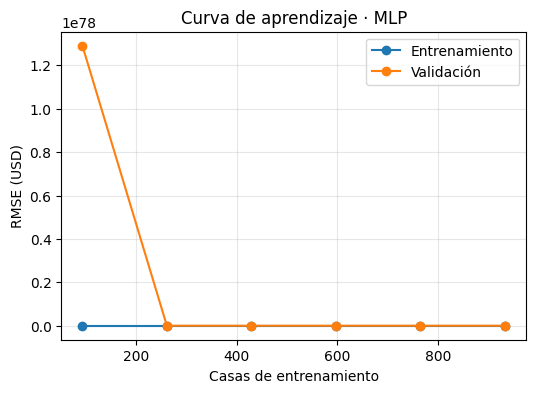

,modelo,RMSE_CV_media_folds,RMSE_OOF,MAE_OOF,RMSE,MAE,R2,MAPE,t_entrenamiento_s,t_busqueda_s
0,MLP,49221.505,53957.052,25561.295,36376.943,24417.634,0.794,0.153,1.053,275.792


In [ ]:
entrenar("MLP", modelo(MLPRegressor(max_iter=3000, early_stopping=True, random_state=SEMILLA), True), {
    "regressor__reg__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
    "regressor__reg__alpha": [1e-3, 1e-2, 1e-1, 1.0],
    "regressor__reg__learning_rate_init": [1e-3, 3e-3],
})

### 9f. Máquina de vector soporte (SVR)

,param_regressor__reg__C,param_regressor__reg__epsilon,param_regressor__reg__gamma,RMSE_CV_media_folds,desv_RMSE_folds
2,1,0.01,0.003,29723.129175,7806.746546
5,1,0.05,0.003,29919.129793,7513.153904
1,1,0.01,0.001,30146.793202,6702.894053
4,1,0.05,0.001,30416.111352,6288.893460
8,1,0.10,0.003,30848.700517,6657.027931


Mejores hiperparámetros: {'regressor__reg__C': 1, 'regressor__reg__epsilon': 0.01, 'regressor__reg__gamma': 0.003}


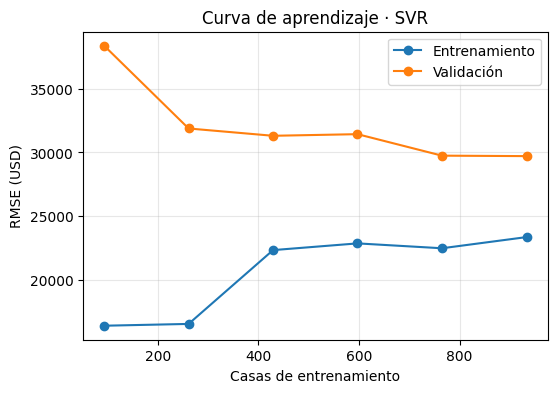

,modelo,RMSE_CV_media_folds,RMSE_OOF,MAE_OOF,RMSE,MAE,R2,MAPE,t_entrenamiento_s,t_busqueda_s
0,SVR,29723.129,30726.29,14528.399,20987.842,13341.409,0.931,0.079,0.427,70.27


In [ ]:
entrenar("SVR", modelo(SVR(kernel="rbf"), True), {
    "regressor__reg__C": [1, 3, 10, 30],
    "regressor__reg__epsilon": [0.01, 0.05, 0.1],
    "regressor__reg__gamma": ["scale", 1e-3, 3e-3],
})

In [ ]:
tabla = pd.DataFrame(resultados).set_index("modelo")
tabla.loc["Base (media)", "RMSE"] = rmse_base

print("Ranking para selección (solo datos de entrenamiento):")
ranking_validacion = tabla.drop(index="Base (media)").sort_values("RMSE_OOF")
display(ranking_validacion.round({
    "RMSE_CV_media_folds": 0, "RMSE_OOF": 0, "MAE_OOF": 0,
    "RMSE": 0, "MAE": 0, "R2": 3, "MAPE": 3,
    "t_entrenamiento_s": 2, "t_busqueda_s": 1,
}))

print("Evaluación final en test (no utilizada para seleccionar modelos):")
ranking_test = tabla.sort_values("RMSE")
display(ranking_test[["RMSE", "MAE", "R2", "MAPE"]].round({
    "RMSE": 0, "MAE": 0, "R2": 3, "MAPE": 3,
}))

Ranking para selección (solo datos de entrenamiento):


,RMSE_CV_media_folds,RMSE_OOF,MAE_OOF,RMSE,MAE,R2,MAPE,t_entrenamiento_s,t_busqueda_s
modelo,,,,,,,,,
XGBoost,27135.0,27384.0,15780.0,24916.0,14456.0,0.903,0.081,1.46,97.3
SVR,29723.0,30726.0,14528.0,20988.0,13341.0,0.931,0.079,0.43,70.3
Bosque aleatorio,30893.0,31085.0,17446.0,24818.0,15149.0,0.904,0.087,5.38,110.9
Lasso,32577.0,33962.0,15928.0,25483.0,15307.0,0.899,0.083,0.21,6.1
Ridge,33844.0,35624.0,15943.0,24643.0,15161.0,0.905,0.082,0.33,8.2
Árbol de decisión,38593.0,38663.0,26662.0,32803.0,22773.0,0.832,0.133,0.07,9.6
Lineal estabilizada (alpha=1e-6),36827.0,40646.0,16812.0,25431.0,16108.0,0.899,0.089,0.26,1.3
MLP,49222.0,53957.0,25561.0,36377.0,24418.0,0.794,0.153,1.05,275.8


Evaluación final en test (no utilizada para seleccionar modelos):


,RMSE,MAE,R2,MAPE
modelo,,,,
SVR,20988.0,13341.0,0.931,0.079
Ridge,24643.0,15161.0,0.905,0.082
Bosque aleatorio,24818.0,15149.0,0.904,0.087
XGBoost,24916.0,14456.0,0.903,0.081
Lineal estabilizada (alpha=1e-6),25431.0,16108.0,0.899,0.089
Lasso,25483.0,15307.0,0.899,0.083
Árbol de decisión,32803.0,22773.0,0.832,0.133
MLP,36377.0,24418.0,0.794,0.153
Base (media),80068.0,NaN,NaN,NaN


**Lectura de las curvas de aprendizaje.**

- **Lineal estabilizada:** utiliza `alpha=1e-6` únicamente para evitar singularidad numérica. Puede conservar una brecha grande y alta varianza con pocos registros; esa penalización mínima no pretende regularizar el modelo para mejorar su generalización.
- **Ridge y Lasso:** sus curvas son más estables y la regularización controla mejor los coeficientes. Una brecha moderada puede permanecer aunque ambas curvas se estabilicen.
- **Árbol de decisión:** si entrenamiento y validación quedan juntos pero con errores altos, existe subajuste provocado por la regularización del árbol.
- **Bosque aleatorio:** normalmente conserva una brecha de varianza, pero reduce la inestabilidad del árbol individual. Si validación continúa descendiendo, más datos podrían ayudar.
- **XGBoost:** alcanza un error de entrenamiento muy bajo y una brecha grande; esto indica sobreajuste parcial. Sin embargo, puede seguir teniendo el menor error OOF y ser el mejor modelo individual según train.
- **MLP:** su resultado OOF debe tener más peso que un test particular favorable. Una validación alta o irregular entre tamaños indica sensibilidad al fold, al `early_stopping` y al tamaño reducido de la muestra.
- **SVR:** suele mostrar una relación más equilibrada entre entrenamiento y validación. Esto indica estabilidad, pero no garantiza por sí solo que tenga el menor error OOF.

Una curva “bonita” o una brecha pequeña no significa automáticamente mejor precisión. Los modelos se seleccionan con métricas OOF; test se utiliza únicamente para estimar el desempeño final y no para cambiar retrospectivamente la selección.

## 10. Análisis de factores del mejor modelo

La importancia por permutación se calcula sobre **train**, no sobre test: mide cuánto empeora el RMSE si se revuelve cada variable original. Se utiliza porque funciona con cualquier modelo, conserva las variables originales del pipeline y se expresa en dólares.

Esta medida describe dependencia predictiva, no causalidad. Cuando existen variables correlacionadas, la importancia puede repartirse entre ellas.

Mejor modelo por RMSE OOF: XGBoost


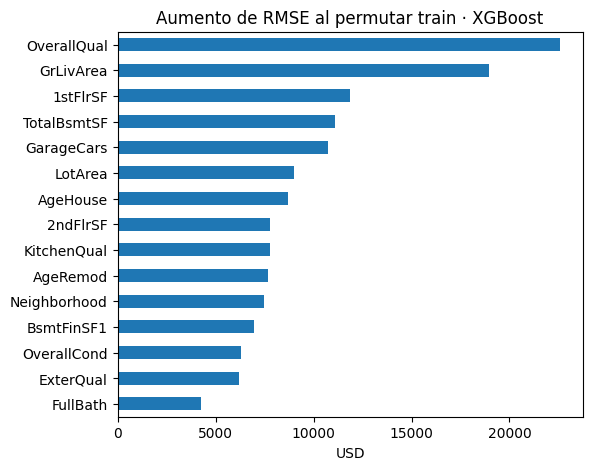

,aumento_RMSE_train_USD
OverallQual,22601.0
GrLivArea,18966.0
1stFlrSF,11883.0
TotalBsmtSF,11078.0
GarageCars,10725.0
LotArea,8981.0
AgeHouse,8680.0
2ndFlrSF,7792.0
KitchenQual,7787.0
AgeRemod,7678.0


In [ ]:
nombre_mejor = tabla.drop(index="Base (media)")["RMSE_OOF"].idxmin()
print("Mejor modelo por RMSE OOF:", nombre_mejor)

imp = permutation_importance(
    mejores[nombre_mejor],
    X_train,
    y_train,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=SEMILLA,
    n_jobs=-1,
)
importancias = pd.Series(
    imp.importances_mean,
    index=X_train.columns,
).sort_values(ascending=False).head(15)

importancias.sort_values().plot.barh(
    figsize=(6, 5),
    title=f"Aumento de RMSE al permutar train · {nombre_mejor}",
)
plt.xlabel("USD")
plt.show()
importancias.round(0).to_frame("aumento_RMSE_train_USD")

**Interpretación.** El modelo elegido por RMSE OOF se interpreta sobre los datos de entrenamiento. Las variables situadas al principio de la gráfica son aquellas cuyo desorden produce el mayor aumento del RMSE.

En términos inmobiliarios suelen agruparse en:

1. **Tamaño habitable**, especialmente `GrLivArea`.
2. **Calidad general**, representada por `OverallQual` y variables de acabados.
3. **Sótano y distribución de la superficie**, como `TotalBsmtSF`, `BsmtFinSF1`, `1stFlrSF` y `2ndFlrSF`.
4. **Terreno, edad, cocina y garaje**.
5. **Vecindario**, cuyo efecto puede compartirse con calidad, tamaño y segmento de vivienda.

El resultado tiene sentido para un valuador, pero no demuestra causalidad. Además, si dos características están correlacionadas, permutar una puede dejar parte de su información disponible en la otra.

## 11. Tres mejores modelos según RMSE + MAE

Se ordenan con `RMSE_OOF + MAE_OOF`, calculados con predicciones fuera de fold sobre train. El conjunto de prueba no participa en esta selección.

**Ventajas de RMSE + MAE.** El RMSE castiga mucho los errores grandes (una casa cara mal valuada pesa más), mientras que el MAE refleja el error típico en dólares y es menos sensible a casos extremos. Sumarlas favorece un modelo que tenga buen error típico **y** pocos errores grandes, que es lo que le importa a una inmobiliaria: valuar bien la mayoría sin equivocarse por mucho en las propiedades caras. **Desventajas**: no tiene una interpretación directa en dólares, mezcla dos escalas que pueden pesar distinto según los datos, y como el RMSE siempre es mayor o igual que el MAE, la suma termina dominada por el RMSE; además ninguna de las dos mide el error relativo (MAPE), que importa en casas baratas.

In [ ]:
tabla_sel = tabla.drop(index="Base (media)").assign(
    RMSE_MAE_OOF=lambda t: t["RMSE_OOF"] + t["MAE_OOF"]
)
top3 = tabla_sel.sort_values("RMSE_MAE_OOF").head(3)
top3[["RMSE_CV_media_folds", "RMSE_OOF", "MAE_OOF", "RMSE_MAE_OOF"]].round(0)

,RMSE_CV_media_folds,RMSE_OOF,MAE_OOF,RMSE_MAE_OOF
modelo,,,,
XGBoost,27135.0,27384.0,15780.0,43164.0
SVR,29723.0,30726.0,14528.0,45255.0
Bosque aleatorio,30893.0,31085.0,17446.0,48531.0


## 12. VotingRegressor y StackingRegressor

- **VotingRegressor**: entrena varios regresores con los mismos datos y predice el **promedio** (opcionalmente ponderado) de sus predicciones. Reduce la varianza cuando los modelos cometen errores distintos; no aprende cómo combinarlos.
- **StackingRegressor**: usa las predicciones de los modelos base, obtenidas con validación cruzada interna, como entradas de un **meta-modelo** (aquí `RidgeCV`) que aprende cuánto confiar en cada uno. Puede superar al promedio, pero cuesta más entrenar y es más difícil de explicar y mantener.

## 13–14. Votación y apilamiento con los tres mejores

In [ ]:
tabla_unica = tabla.loc[~tabla.index.duplicated(keep="last")].copy()
tabla_unica = tabla_unica.drop(index="Base (media)", errors="ignore")
tabla_unica["RMSE_MAE_OOF"] = tabla_unica["RMSE_OOF"] + tabla_unica["MAE_OOF"]
top3 = tabla_unica.sort_values("RMSE_MAE_OOF").head(3)

print("Modelos únicos seleccionados:", top3.index.tolist())

# sklearn exige nombres internos únicos; no se usan los nombres de los modelos como claves.
base3 = [
    (f"modelo_{i + 1}", clone(mejores[nombre]))
    for i, nombre in enumerate(top3.index)
]
conjuntos = {
    "Voting (top 3)": VotingRegressor(base3, n_jobs=-1),
    "Stacking (top 3)": StackingRegressor(
        base3,
        final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 13)),
        cv=cv,
        n_jobs=-1,
    ),
}
filas = []
for nombre, est in conjuntos.items():
    t0 = time.perf_counter(); est.fit(X_train, y_train); t = time.perf_counter() - t0
    pred = est.predict(X_test)
    filas.append({"modelo": nombre, "RMSE": root_mean_squared_error(y_test, pred), "MAE": mean_absolute_error(y_test, pred),
                  "R2": r2_score(y_test, pred), "MAPE": mean_absolute_percentage_error(y_test, pred), "t_entrenamiento_s": t})
comparacion = pd.concat([tabla.loc[top3.index, ["RMSE", "MAE", "R2", "MAPE", "t_entrenamiento_s"]],
                         pd.DataFrame(filas).set_index("modelo")])
comparacion.round({"RMSE": 0, "MAE": 0, "R2": 3, "MAPE": 3, "t_entrenamiento_s": 2})

Modelos únicos seleccionados: ['XGBoost', 'SVR', 'Bosque aleatorio']


,RMSE,MAE,R2,MAPE,t_entrenamiento_s
modelo,,,,,
XGBoost,24916.0,14456.0,0.903,0.081,1.46
SVR,20988.0,13341.0,0.931,0.079,0.43
Bosque aleatorio,24818.0,15149.0,0.904,0.087,5.38
Voting (top 3),22457.0,13347.0,0.921,0.077,6.41
Stacking (top 3),23549.0,14453.0,0.913,0.081,38.16


## 15. ¿Conviene usar un modelo conjunto?

En el conjunto de prueba se obtuvieron estos resultados principales:

- **SVR:** RMSE 20,988 USD; MAE 13,341; R² 0.931; MAPE 7.9 %.
- **Stacking:** RMSE 23,549 USD; MAE 14,453; R² 0.913; MAPE 8.1 %.
- **Voting:** RMSE 22,457 USD; MAE 13,347; R² 0.921; MAPE 7.7 %.
- **XGBoost:** RMSE 24,916 USD; MAE 14,456; R² 0.903; MAPE 8.1 %.

Ningún ensemble mejoró el RMSE del mejor modelo individual en este test. Voting sí obtuvo el menor MAPE y un MAE casi igual al de SVR, pero la diferencia no justifica automáticamente mantener tres pipelines.

**Decisión:** con RMSE como métrica principal, no existe evidencia suficiente para recomendar el ensemble. XGBoost se mantiene como candidato principal porque obtuvo el menor RMSE OOF (27,384 USD), que fue el criterio definido antes de observar test. SVR también debe conservarse como candidato porque fue el mejor individual en el test. La decisión productiva debe confirmarse con validación repetida o datos externos, no escogiendo retrospectivamente el ganador de este test.

## 16. Reportes finales

### a) Para el equipo técnico

- **Candidato principal:** XGBoost (`n_estimators=1000`, `learning_rate=0.1`, `max_depth=4`, `subsample=0.85`, `colsample_bytree=0.3`, `reg_lambda=5`) dentro de un pipeline con imputación y One-Hot, entrenado sobre `log(1 + SalePrice)`.
- **Validación:** RMSE medio por folds 27,135 USD; RMSE OOF global 27,384; MAE OOF 15,780.
- **Test:** XGBoost obtuvo RMSE 24,916, MAE 14,456, R² 0.903 y MAPE 8.1 %. El modelo base obtuvo RMSE 80,068.
- **Comparación:** SVR obtuvo mejor RMSE de test, pero peor RMSE OOF. Esta diferencia muestra la variabilidad de una sola partición y no autoriza seleccionar SVR usando test.
- **Riesgos:** XGBoost conserva una brecha entre entrenamiento y validación. Se recomienda validación repetida, análisis por rango de precio y monitoreo de drift.
- **Costo:** los tiempos dependen del equipo y la paralelización. Deben interpretarse de forma relativa, no como un SLA de producción.
- **Operación:** versionar el pipeline completo, registrar versiones, vigilar categorías nuevas y reentrenar cuando exista evidencia de deterioro.

### b) Para el director de la inmobiliaria

- En el test, XGBoost tuvo un error absoluto promedio cercano a **14,456 dólares**, aproximadamente **8.1 %** del precio, y explicó **90.3 %** de la variación observada.
- El modelo ingenuo presentó RMSE cercano a 80,068 dólares, por lo que los modelos entrenados representan una mejora amplia.
- Las señales principales fueron tamaño habitable, calidad general, sótano, terreno, antigüedad, cocina y garaje.
- La herramienta puede apoyar una primera valuación y detectar casos para revisión, pero no sustituye al valuador.
- Los datos corresponden a Ames, Iowa, entre 2006 y 2010; antes de usar el sistema en otro mercado debe validarse con ventas recientes y locales.

## 17. Conclusiones de la actividad

XGBoost fue el mejor modelo individual según predicciones OOF, mientras SVR obtuvo el menor RMSE en el test particular. Esta diferencia demuestra que una sola partición puede favorecer a un modelo y que test no debe utilizarse para cambiar retrospectivamente la selección. Voting y Stacking no mejoraron el RMSE de SVR, por lo que su complejidad adicional no se justifica bajo la métrica principal.

El preprocesamiento dentro de pipelines evitó fuga de información y permitió aplicar de manera consistente imputación, codificación y transformación. Las importancias identifican asociaciones predictivas, no relaciones causales.

Los resultados deben considerarse preliminares: el conjunto contiene 1,460 ventas de Ames entre 2006 y 2010. Transformar las edades respecto a 2026 no actualiza los precios por inflación ni por cambios del mercado. Antes de utilizar el modelo para valuaciones actuales debe validarse y reentrenarse con ventas recientes y locales.

Finalmente, la intervención humana fue indispensable para detectar fuga del objetivo, inestabilidad numérica, diferencias entre CV y OOF y resultados excesivamente optimistas que el código por sí solo no identificaba como incorrectos.

# **Conclusiones**

### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

**¿En qué casos el uso de LLMs fue de mayor provecho?**  
Los LLM fueron útiles para organizar el flujo de trabajo, proponer pipelines de preprocesamiento, definir espacios iniciales de búsqueda para las ocho variantes, generar código repetitivo de validación cruzada y estructurar curvas, tablas y reportes. También ayudaron a explicar conceptos como fuga de información, métricas OOF, Voting y Stacking. Sus respuestas se utilizaron como propuestas iniciales y no como resultados definitivos.

**¿En cuáles casos fue indispensable la intervención de los expertos?**  
La revisión humana fue necesaria para comprobar que el código y las conclusiones fueran metodológicamente correctos. En una ejecución inicial se obtuvo un R² de 0.999 y `SalePrice` apareció como la variable más importante porque el objetivo se había incluido accidentalmente como entrada. Aunque el código terminó sin errores, el resultado era incorrecto por fuga de información.

También fue necesario:

- mantener test fuera de la selección de modelos;
- distinguir el RMSE medio por folds del RMSE OOF global;
- detectar la inestabilidad numérica de la regresión lineal;
- evitar modelos duplicados al reejecutar celdas;
- revisar la inestabilidad del MLP entre folds;
- separar el ganador de validación del ganador del test particular;
- comprobar que Voting y Stacking no necesariamente mejoran al mejor modelo individual.

La principal conclusión es que un LLM puede acelerar el desarrollo y ayudar a explorar alternativas, pero la responsabilidad de validar los datos, el código, las métricas y las conclusiones permanece en el equipo.

### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **Anexo**

**Incluir a continuación los prompts que consideren hayan sido los más importantes, así como el nombre del modelo LLM utilizado.**

### +++++++++++ Inicia sección de prompts ++++++++++++++++

**Modelos LLM utilizados:** Claude (Anthropic), modelo Claude Opus 5.5 mediante Claude Code, durante el desarrollo inicial; GPT-5.6 Sol mediante Cursor durante la auditoría y corrección final.

Los siguientes prompts se utilizaron como guía durante la revisión y corrección final del notebook:

#### 1. Preprocesamiento y control de fuga

> Analiza el conjunto `train.csv` de House Prices y diseña un preprocesamiento sin fuga de información. `SalePrice` debe utilizarse únicamente como objetivo y `Id` debe eliminarse. Distingue faltantes que significan ausencia de aquellos que requieren imputación. Coloca imputación, transformación Yeo–Johnson, codificación ordinal y One-Hot Encoding dentro de un `Pipeline` y `ColumnTransformer`. Ajusta todas las transformaciones únicamente con train. Explica y verifica por código dónde podría ocurrir data leakage.

#### 2. Comparación de representaciones de `MoSold`

> Compara cuatro tratamientos para `MoSold`: conservarlo como número, eliminarlo, tratarlo como categoría mediante One-Hot Encoding y representarlo cíclicamente con seno y coseno. Utiliza exactamente la misma partición de entrenamiento, el mismo modelo Ridge y validación cruzada de cinco folds. Reporta RMSE medio y selecciona la alternativa sin observar test. Explica si la diferencia encontrada es suficientemente grande para considerarse importante.

#### 3. Búsqueda de hiperparámetros y validación cruzada

> Ajusta regresión lineal, Ridge, Lasso, árbol de decisión, Random Forest, XGBoost, MLP y SVR. Utiliza pipelines completos y búsqueda de hiperparámetros con cinco folds. Mantén test fuera de la selección. Distingue entre RMSE promedio de los folds y RMSE global de predicciones OOF. Reporta RMSE, MAE, R², MAPE, tiempos y mejores hiperparámetros. Asegura reproducibilidad con una semilla fija y evita resultados duplicados si una celda se ejecuta nuevamente.

#### 4. Curvas de aprendizaje

> Genera curvas de aprendizaje para cada modelo utilizando RMSE de entrenamiento y validación. Analiza sesgo, varianza, estabilidad y posible beneficio de obtener más datos. No concluyas que una curva es mejor solamente porque la brecha train–validación es pequeña; considera también el nivel absoluto del RMSE. Presta especial atención a la inestabilidad del MLP y al sobreajuste de XGBoost.

#### 5. Voting, Stacking e interpretación de resultados

> Selecciona los tres mejores modelos usando únicamente `RMSE_OOF + MAE_OOF`. Construye un `VotingRegressor` que promedie sus predicciones y un `StackingRegressor` con `RidgeCV` como metamodelo. Utiliza nombres internos únicos y predicciones fuera de fold para evitar fuga. Evalúa los modelos individuales y ensembles una sola vez en test. Compara precisión, costo, complejidad y mantenibilidad, y explica por qué el modelo con mejor test no debe seleccionarse retrospectivamente si otro ganó en validación.

Las propuestas de los LLM se verificaron contra las salidas del código. La intervención humana permitió detectar fuga del objetivo, diferencias entre métricas CV y OOF, inestabilidad numérica y resultados duplicados por reejecución de celdas.

### +++++++++++ Termina sección de prompts ++++++++++++++++

# **<<< Fin de la Actividad de la Semana - Predicción de Precios de Casas >>>**